# SWA2124 — Google Local Guides Review Ratings

**Dataset:** Travel/Google review ratings — 5,456 users, average rating (0–5) given per attraction category across 24 categories (churches, resorts, beaches, parks, theatres, museums, malls, zoos, restaurants, pubs/bars, local services, burger/pizza shops, hotels, juice bars, art galleries, dance clubs, swimming pools, gyms, bakeries, beauty & spas, cafes, view points, monuments, gardens).


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import pandas as pd
import numpy as np

# In Colab: upload the file via the Files pane, or mount Drive, then update this path
FILE_PATH = "google_review_ratings.csv"

df_raw = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/google_review_ratings.csv")
print(df_raw.shape)
df_raw.head()

(5456, 26)


,User,Category 1,Category 2,Category 3,Category 4,Category 5,Category 6,Category 7,Category 8,Category 9,...,Category 16,Category 17,Category 18,Category 19,Category 20,Category 21,Category 22,Category 23,Category 24,Unnamed: 25
0,User 1,0.0,0.0,3.63,3.65,5.0,2.92,5.0,2.35,2.33,...,0.59,0.5,0.0,0.5,0.0,0.0,0.0,0.0,0.0,NaN
1,User 2,0.0,0.0,3.63,3.65,5.0,2.92,5.0,2.64,2.33,...,0.59,0.5,0.0,0.5,0.0,0.0,0.0,0.0,0.0,NaN
2,User 3,0.0,0.0,3.63,3.63,5.0,2.92,5.0,2.64,2.33,...,0.59,0.5,0.0,0.5,0.0,0.0,0.0,0.0,0.0,NaN
3,User 4,0.0,0.5,3.63,3.63,5.0,2.92,5.0,2.35,2.33,...,0.59,0.5,0.0,0.5,0.0,0.0,0.0,0.0,0.0,NaN
4,User 5,0.0,0.0,3.63,3.63,5.0,2.92,5.0,2.64,2.33,...,0.59,0.5,0.0,0.5,0.0,0.0,0.0,0.0,0.0,NaN


## 1. Initial profiling

In [ ]:
print(df_raw.dtypes)
print()
print(df_raw.isna().sum())

User            object
Category 1     float64
Category 2     float64
Category 3     float64
Category 4     float64
Category 5     float64
Category 6     float64
Category 7     float64
Category 8     float64
Category 9     float64
Category 10    float64
Category 11     object
Category 12    float64
Category 13    float64
Category 14    float64
Category 15    float64
Category 16    float64
Category 17    float64
Category 18    float64
Category 19    float64
Category 20    float64
Category 21    float64
Category 22    float64
Category 23    float64
Category 24    float64
Unnamed: 25    float64
dtype: object

User              0
Category 1        0
Category 2        0
Category 3        0
Category 4        0
Category 5        0
Category 6        0
Category 7        0
Category 8        0
Category 9        0
Category 10       0
Category 11       0
Category 12       1
Category 13       0
Category 14       0
Category 15       0
Category 16       0
Category 17       0
Category 18       0
Categor

## 2. Fix known structural issues



In [ ]:
df = df_raw.copy()

# Strip whitespace from column names
df.columns = [c.strip() for c in df.columns]

# Rows where a value bled into the phantom column
shifted_rows = df[df['Unnamed: 25'].notna()]
print("Rows with column misalignment:")
print(shifted_rows[['User', 'Category 11', 'Category 22', 'Category 23', 'Category 24', 'Unnamed: 25']])

Rows with column misalignment:
           User Category 11  Category 22  Category 23  Category 24  \
1347  User 1348           5          5.0         0.26          NaN   
2712  User 2713       2\t2.          5.0         5.00         2.57   

      Unnamed: 25  
1347         1.04  
2712         2.58  


In [ ]:
# Drop the 2 rows we can't reliably realign, and the phantom column
bad_users = shifted_rows['User'].tolist()
print("Dropping:", bad_users)

df = df[~df['User'].isin(bad_users)].copy()
df = df.drop(columns=['Unnamed: 25'])
print(df.shape)

Dropping: ['User 1348', 'User 2713']
(5454, 25)


## 3. Enforce numeric types

In [ ]:
category_cols = [c for c in df.columns if c.startswith('Category')]

for col in category_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')

print(df[category_cols].dtypes.unique())
print(df[category_cols].isna().sum().sum(), "remaining NaNs after coercion")

[dtype('float64')]
0 remaining NaNs after coercion


## 4. Handle missing values







In [ ]:
na_before = df[category_cols].isna().sum()
print(na_before[na_before > 0])

for col in category_cols:
    if df[col].isna().any():
        df[col] = df[col].fillna(df[col].median())

print("Remaining NaNs:", df[category_cols].isna().sum().sum())

Series([], dtype: int64)
Remaining NaNs: 0


## 5. Check duplicates and value ranges

In [ ]:
print("Duplicate users:", df['User'].duplicated().sum())
print()
print(df[category_cols].describe().T[['min', 'max', 'mean']])

# Flag any out-of-range ratings (expected 0-5)
out_of_range = ((df[category_cols] < 0) | (df[category_cols] > 5)).sum()
print()
print("Out-of-range values per column:")
print(out_of_range[out_of_range > 0])

Duplicate users: 0

              min  max      mean
Category 1   0.00  5.0  1.455746
Category 2   0.00  5.0  2.320048
Category 3   0.00  5.0  2.489059
Category 4   0.83  5.0  2.797103
Category 5   1.12  5.0  2.958904
Category 6   1.11  5.0  2.893423
Category 7   1.12  5.0  3.351476
Category 8   0.86  5.0  2.541177
Category 9   0.84  5.0  3.126542
Category 10  0.81  5.0  2.832695
Category 11  0.78  5.0  2.549622
Category 12  0.78  5.0  2.078401
Category 13  0.77  5.0  2.125820
Category 14  0.76  5.0  2.190429
Category 15  0.00  5.0  2.206140
Category 16  0.00  5.0  1.192710
Category 17  0.00  5.0  0.949349
Category 18  0.00  5.0  0.822525
Category 19  0.00  5.0  0.969250
Category 20  0.00  5.0  0.999626
Category 21  0.00  5.0  0.965275
Category 22  0.00  5.0  1.749345
Category 23  0.00  5.0  1.531051
Category 24  0.00  5.0  1.560570

Out-of-range values per column:
Series([], dtype: int64)


## 6. Zeros vs. missing — decision point

Zeros are common across several category columns. Before modelling, decide (as a group) whether 0.0 means:
- **a genuine low rating**, or
- **the user never rated/visited that category** (functionally missing).

This cell just quantifies it so you can discuss and document the decision in your methodology section — it doesn't change the data.

In [ ]:
zero_counts = (df[category_cols] == 0).sum().sort_values(ascending=False)
zero_pct = (zero_counts / len(df) * 100).round(1)
pd.DataFrame({'zero_count': zero_counts, 'zero_pct': zero_pct})

,zero_count,zero_pct
Category 19,1045,19.2
Category 18,1016,18.6
Category 20,895,16.4
Category 21,603,11.1
Category 17,478,8.8
Category 22,345,6.3
Category 23,302,5.5
Category 24,225,4.1
Category 1,195,3.6
Category 16,112,2.1


In [ ]:
# Check: are zeros scattered randomly, or concentrated in users who also have
# few non-zero categories overall? (supports "non-response" over "genuine rating")
df['zero_count'] = (df[category_cols] == 0).sum(axis=1)
print(df['zero_count'].value_counts().sort_index())

# Check: is 0 an outlier vs. the next-lowest real ratings, or part of a smooth distribution?
for col in ['Category 17', 'Category 18', 'Category 19']:  # your worst offenders
    vals = df[col][df[col] > 0].sort_values()
    print(col, "smallest non-zero values:", vals.head(5).tolist())

zero_count
0    3724
1     505
2     167
3     457
4     243
5     147
6     114
7      69
8      22
9       6
Name: count, dtype: int64
Category 17 smallest non-zero values: [0.5, 0.5, 0.5, 0.5, 0.5]
Category 18 smallest non-zero values: [0.5, 0.5, 0.5, 0.5, 0.5]
Category 19 smallest non-zero values: [0.5, 0.5, 0.5, 0.5, 0.5]


In [ ]:
## 6b. Treat documented-invalid zeros as missing (not genuine low ratings)
# UCI's own documentation states the rating scale is 1–5, not 0–5 (Renjith et al., 2018).
# A 0.0 therefore falls outside the valid scale and represents "not rated/visited",
# not a genuine terrible rating. We convert these to NaN and impute.

for col in category_cols:
    df[col] = df[col].replace(0.0, np.nan)

print(df[category_cols].isna().sum()[df[category_cols].isna().sum() > 0])

# Re-impute with column median (same approach as Section 4, now applied to true zeros)
for col in category_cols:
    if df[col].isna().any():
        df[col] = df[col].fillna(df[col].median())

print("Remaining NaNs:", df[category_cols].isna().sum().sum())

Category 1      195
Category 2       90
Category 3        4
Category 15       4
Category 16     112
Category 17     478
Category 18    1016
Category 19    1045
Category 20     895
Category 21     603
Category 22     345
Category 23     302
Category 24     225
dtype: int64
Remaining NaNs: 0


In [ ]:
high_missing_cols = ['Category 17', 'Category 18', 'Category 19', 'Category 20', 'Category 21']
for col in high_missing_cols:
    df[f'{col}_not_rated'] = (df_raw[col].fillna(0) == 0).astype(int)  # flag before imputation overwrote it

In [ ]:
## 6c. Add "not rated" indicators for high-missingness categories
# Preserves the non-visitation signal that flat median imputation erases —
# useful for clustering, since it's a real behavioural signal, not noise.

high_missing_cols = ['Category 17', 'Category 18', 'Category 19', 'Category 20', 'Category 21']

# Match back to df_raw on User to recover original zero/non-zero status
raw_lookup = df_raw.set_index('User')

for col in high_missing_cols:
    df[f'{col}_not_rated'] = df['User'].map(raw_lookup[col]).eq(0.0).astype(int)

print(df[[f'{c}_not_rated' for c in high_missing_cols]].sum())

Category 17_not_rated     478
Category 18_not_rated    1016
Category 19_not_rated    1045
Category 20_not_rated     895
Category 21_not_rated     603
dtype: int64


## 7. Export cleaned dataset

In [ ]:
df.to_csv("google_review_ratings_cleaned.csv", index=False)
print("Saved:", df.shape)
df.head()

Saved: (5454, 31)


,User,Category 1,Category 2,Category 3,Category 4,Category 5,Category 6,Category 7,Category 8,Category 9,...,Category 21,Category 22,Category 23,Category 24,zero_count,Category 17_not_rated,Category 18_not_rated,Category 19_not_rated,Category 20_not_rated,Category 21_not_rated
0,User 1,1.35,1.97,3.63,3.65,5.0,2.92,5.0,2.35,2.33,...,0.8,1.07,1.1,1.31,8,0,1,0,1,1
1,User 2,1.35,1.97,3.63,3.65,5.0,2.92,5.0,2.64,2.33,...,0.8,1.07,1.1,1.31,8,0,1,0,1,1
2,User 3,1.35,1.97,3.63,3.63,5.0,2.92,5.0,2.64,2.33,...,0.8,1.07,1.1,1.31,8,0,1,0,1,1
3,User 4,1.35,0.50,3.63,3.63,5.0,2.92,5.0,2.35,2.33,...,0.8,1.07,1.1,1.31,7,0,1,0,1,1
4,User 5,1.35,1.97,3.63,3.63,5.0,2.92,5.0,2.64,2.33,...,0.8,1.07,1.1,1.31,8,0,1,0,1,1


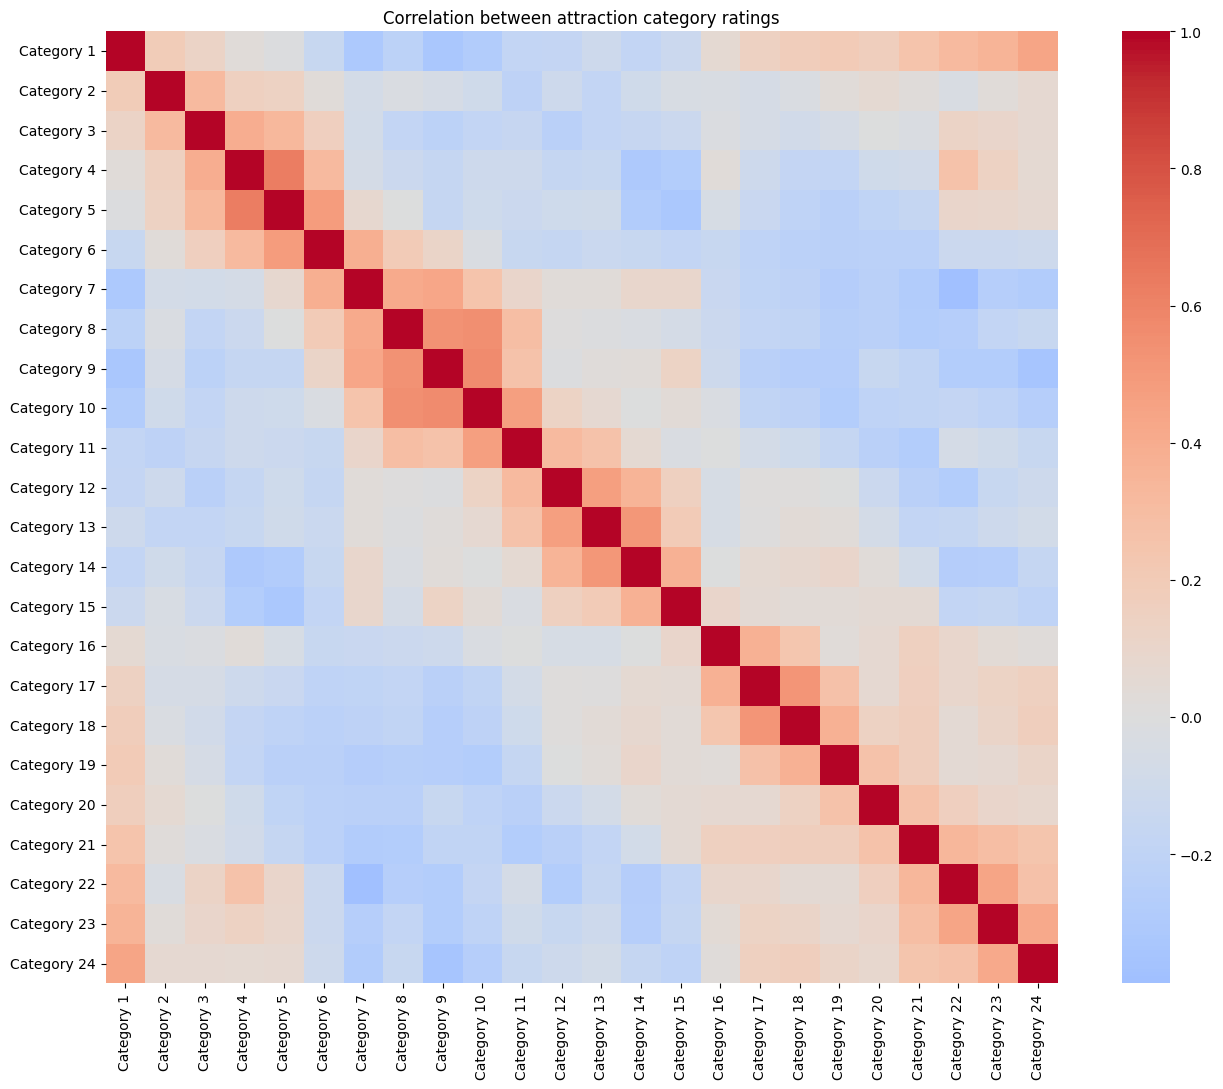

Top 10 correlated category pairs:
Category 5   Category 4     0.626787
Category 10  Category 9     0.564442
             Category 8     0.551613
Category 8   Category 9     0.536705
Category 17  Category 18    0.519064
Category 13  Category 14    0.512732
Category 6   Category 5     0.489528
Category 13  Category 12    0.470310
Category 10  Category 11    0.469282
Category 1   Category 24    0.440490
dtype: float64


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

## 8. Exploratory Data Analysis

# Correlation heatmap across the 24 rating categories
plt.figure(figsize=(14, 11))
corr = df[category_cols].corr()
sns.heatmap(corr, cmap='coolwarm', center=0, annot=False, square=True)
plt.title('Correlation between attraction category ratings')
plt.tight_layout()
plt.show()

# Which category pairs are most strongly correlated? (excludes self-correlation)
corr_pairs = corr.where(~np.eye(len(corr), dtype=bool)).unstack().dropna()
corr_pairs = corr_pairs.sort_values(ascending=False).drop_duplicates()
print("Top 10 correlated category pairs:")
print(corr_pairs.head(10))

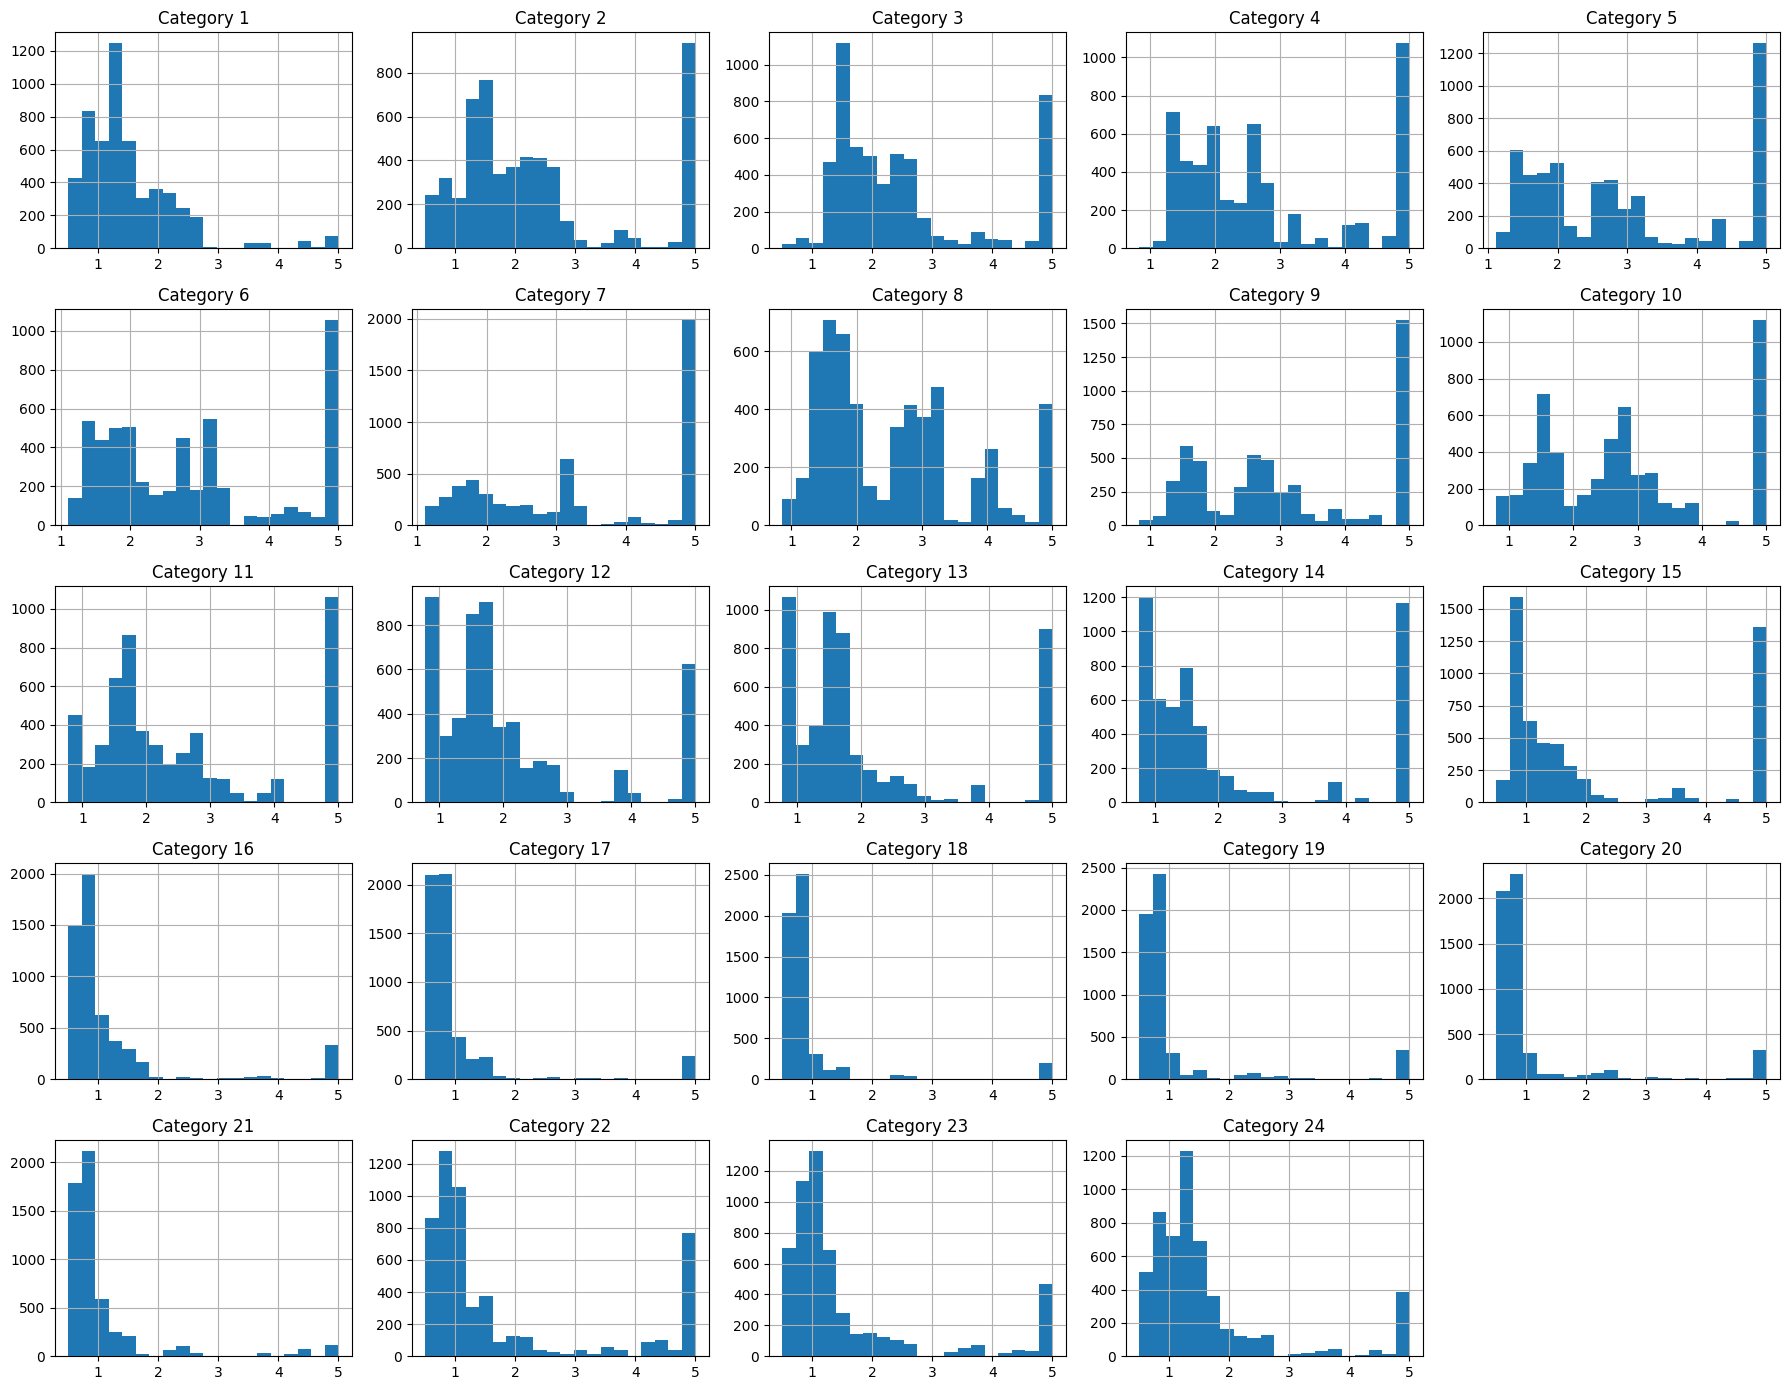

In [ ]:
# Distribution of ratings per category (grid of histograms)
df[category_cols].hist(figsize=(18, 14), bins=20)
plt.tight_layout()
plt.show()

In [ ]:
# Skewness check — informs whether median (robust) vs mean imputation was the right call,
# and flags categories that might behave oddly in distance-based clustering
skew = df[category_cols].skew().sort_values(ascending=False)
print(skew)

Category 18    3.942615
Category 17    3.607405
Category 21    3.287947
Category 19    2.844595
Category 20    2.766676
Category 16    2.763853
Category 24    2.065774
Category 1     2.043080
Category 23    1.858402
Category 12    1.388079
Category 22    1.294849
Category 13    1.263766
Category 3     1.092137
Category 14    1.034112
Category 2     0.950295
Category 15    0.865323
Category 11    0.817109
Category 8     0.772499
Category 4     0.706816
Category 6     0.558540
Category 10    0.524048
Category 5     0.487415
Category 9     0.272911
Category 7     0.017658
dtype: float64


# SWA2124 — Modeling: User Segmentation (Clustering) + Predictive Classification


1. Scales features
2. Uses PCA to check dimensionality / multicollinearity
3. Finds an optimal number of clusters (Elbow + Silhouette)
4. Runs K-Means to segment users into behavioral groups
5. Profiles each segment (what makes it distinct)
6. Trains a classifier to **predict segment membership** — this is the "predictive analysis" component required by the assignment
7. Evaluates the classifier and exports outputs for Power BI


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
from sklearn.model_selection import cross_val_score, StratifiedKFold

RANDOM_STATE = 42  # set once, reuse everywhere for reproducibility

# df, category_cols, and flag_cols already exist from cleaning — just confirm them
category_cols = [c for c in df.columns if c.startswith("Category") and "_not_rated" not in c]
flag_cols = [c for c in df.columns if c.endswith("_not_rated")]
print(df.shape)
print("Category columns:", len(category_cols))
print("Flag columns:", flag_cols)

(5454, 31)
Category columns: 24
Flag columns: ['Category 17_not_rated', 'Category 18_not_rated', 'Category 19_not_rated', 'Category 20_not_rated', 'Category 21_not_rated']


##1. Feature scaling

All 24 ratings are already on the same 0–5 scale, but K-Means is distance-based and still
sensitive to differences in variance across columns (see the skewness check from cleaning).
Standardizing puts every feature on a comparable footing before clustering.

In [ ]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[category_cols])
X_scaled = pd.DataFrame(X_scaled, columns=category_cols, index=df.index)
X_scaled.describe().T[['mean', 'std']].head()


,mean,std
Category 1,7.816752e-17,1.000092
Category 2,-2.605584e-18,1.000092
Category 3,9.119544e-18,1.000092
Category 4,-1.654546e-16,1.000092
Category 5,3.152757e-16,1.000092


## 2. Multicollinearity check via PCA



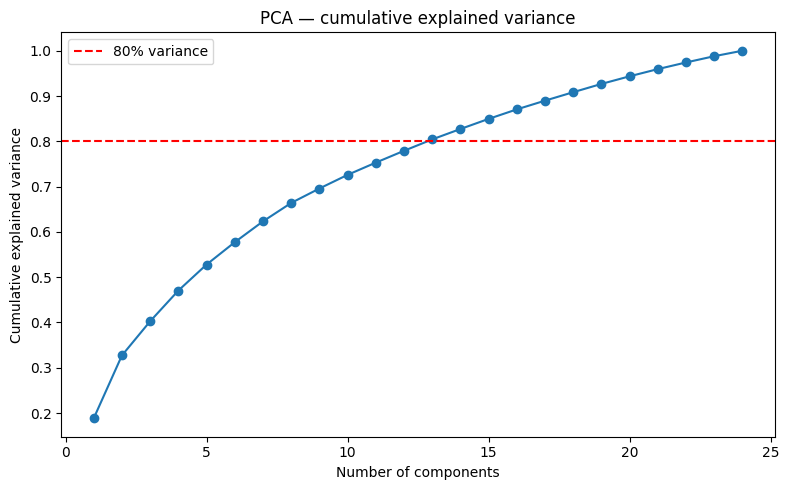

Components needed for 80% variance: 13


In [ ]:
pca_full = PCA(random_state=RANDOM_STATE).fit(X_scaled)
explained = np.cumsum(pca_full.explained_variance_ratio_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, len(explained) + 1), explained, marker='o')
plt.axhline(0.80, color='red', linestyle='--', label='80% variance')
plt.xlabel('Number of components')
plt.ylabel('Cumulative explained variance')
plt.title('PCA — cumulative explained variance')
plt.legend()
plt.tight_layout()
plt.show()

n_components_80 = np.argmax(explained >= 0.80) + 1
print(f"Components needed for 80% variance: {n_components_80}")


In [ ]:
# 2D projection, just for visualizing clusters later (not used as model input)
pca_2d = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca_2d = pca_2d.fit_transform(X_scaled)
print("Variance explained by first 2 components:", pca_2d.explained_variance_ratio_.sum().round(3))


Variance explained by first 2 components: 0.327


## 3. Choosing the number of clusters (k)

Two standard methods, used together:
- **Elbow method** (within-cluster sum of squares / inertia) — look for the "bend"
- **Silhouette score** — how well-separated the clusters are (higher is better, range -1 to 1)

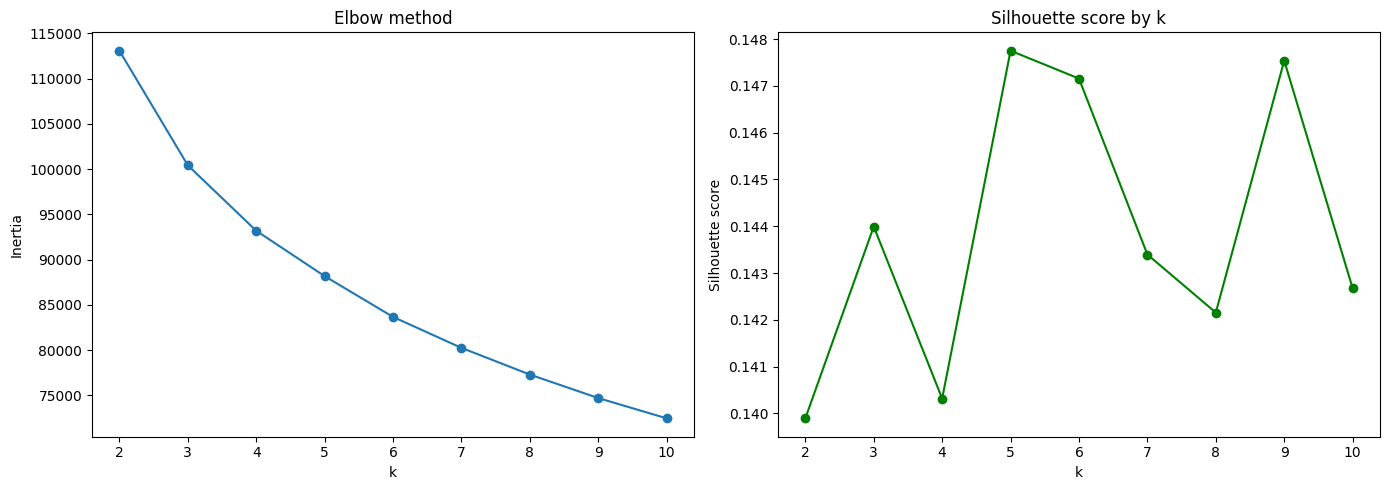

k=2: silhouette=0.140
k=3: silhouette=0.144
k=4: silhouette=0.140
k=5: silhouette=0.148
k=6: silhouette=0.147
k=7: silhouette=0.143
k=8: silhouette=0.142
k=9: silhouette=0.148
k=10: silhouette=0.143


In [ ]:
inertias = []
silhouettes = []
k_range = range(2, 11)

for k in k_range:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_scaled, labels))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(list(k_range), inertias, marker='o')
axes[0].set_xlabel('k')
axes[0].set_ylabel('Inertia')
axes[0].set_title('Elbow method')

axes[1].plot(list(k_range), silhouettes, marker='o', color='green')
axes[1].set_xlabel('k')
axes[1].set_ylabel('Silhouette score')
axes[1].set_title('Silhouette score by k')
plt.tight_layout()
plt.show()

for k, s in zip(k_range, silhouettes):
    print(f"k={k}: silhouette={s:.3f}")


In [ ]:
N_CLUSTERS = 4  # <-- UPDATE based on the elbow/silhouette plot above, then justify your choice in the report

kmeans = KMeans(n_clusters=N_CLUSTERS, random_state=RANDOM_STATE, n_init=10)
df['cluster'] = kmeans.fit_predict(X_scaled)
print(df['cluster'].value_counts().sort_index())


cluster
0    2043
1     962
2    1812
3     637
Name: count, dtype: int64


## 4. Visualize clusters (PCA 2D projection)

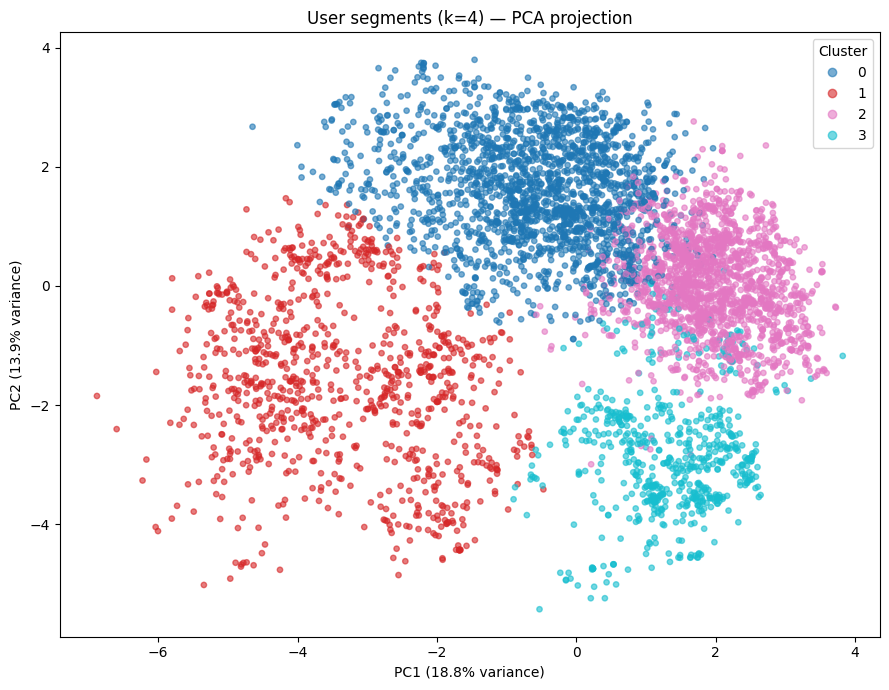

In [ ]:
plt.figure(figsize=(9, 7))
scatter = plt.scatter(X_pca_2d[:, 0], X_pca_2d[:, 1], c=df['cluster'], cmap='tab10', alpha=0.6, s=15)
plt.xlabel(f'PC1 ({pca_2d.explained_variance_ratio_[0]*100:.1f}% variance)')
plt.ylabel(f'PC2 ({pca_2d.explained_variance_ratio_[1]*100:.1f}% variance)')
plt.title(f'User segments (k={N_CLUSTERS}) — PCA projection')
plt.legend(*scatter.legend_elements(), title='Cluster')
plt.tight_layout()
plt.show()


## 5. Profile each cluster





In [ ]:
cluster_profile = df.groupby('cluster')[category_cols].mean().round(2)
cluster_profile


,Category 1,Category 2,Category 3,Category 4,Category 5,Category 6,Category 7,Category 8,Category 9,Category 10,...,Category 15,Category 16,Category 17,Category 18,Category 19,Category 20,Category 21,Category 22,Category 23,Category 24
cluster,,,,,,,,,,,,,,,,,,,,,
0,1.52,2.65,3.24,3.96,4.21,3.56,3.27,2.28,2.64,2.48,...,1.40,1.12,0.85,0.74,0.81,0.93,0.91,2.23,1.87,1.73
1,2.36,2.59,2.39,2.16,2.04,1.86,2.00,1.60,1.81,1.67,...,2.42,1.86,1.99,1.95,2.37,2.11,1.94,2.74,2.46,2.62
2,1.18,2.25,1.98,2.21,2.46,3.07,4.24,3.53,4.46,3.84,...,2.42,0.97,0.71,0.70,0.75,0.81,0.80,1.13,1.03,1.14
3,1.08,1.33,1.70,1.68,1.77,1.82,3.11,2.00,2.89,2.88,...,3.88,1.20,0.95,0.92,1.23,1.13,0.90,1.04,0.99,1.07


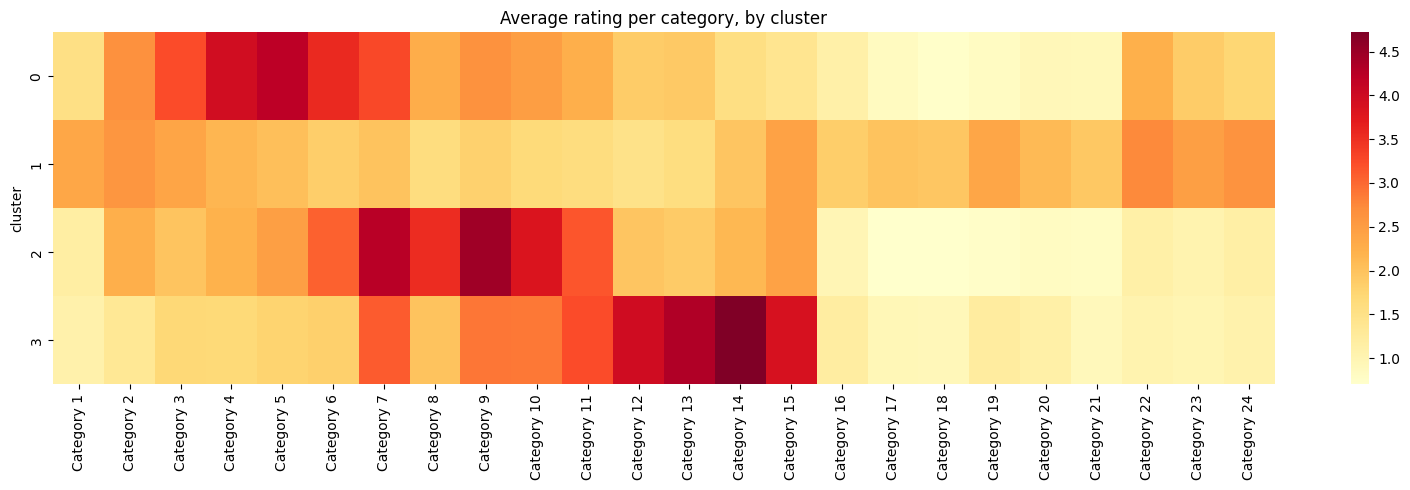


Cluster 0 (n=2043) — top distinguishing categories:
Category 5    1.251096
Category 4    1.162897
Category 3    0.749426
dtype: float64
Cluster 0 — lowest categories:
Category 9    -0.486542
Category 14   -0.640429
Category 15   -0.807116
dtype: float64

Cluster 1 (n=962) — top distinguishing categories:
Category 19    1.255132
Category 24    1.005387
Category 18    0.989624
dtype: float64
Cluster 1 — lowest categories:
Category 10   -1.162695
Category 9    -1.316542
Category 7    -1.351476
dtype: float64

Cluster 2 (n=1812) — top distinguishing categories:
Category 9     1.333458
Category 10    1.007305
Category 8     0.988823
dtype: float64
Cluster 2 — lowest categories:
Category 23   -0.561960
Category 4    -0.587103
Category 22   -0.687030
dtype: float64

Cluster 3 (n=637) — top distinguishing categories:
Category 14    2.529571
Category 13    2.194180
Category 12    1.901599
dtype: float64
Cluster 3 — lowest categories:
Category 6   -1.073423
Category 4   -1.117103
Category 5   -

In [ ]:
# Heatmap makes differences between clusters easier to read than a raw table
plt.figure(figsize=(16, 5))
sns.heatmap(cluster_profile, cmap='YlOrRd', annot=False)
plt.title('Average rating per category, by cluster')
plt.tight_layout()
plt.show()

# For each cluster, which categories stand out most vs. the overall average?
overall_mean = df[category_cols].mean()
for c in sorted(df['cluster'].unique()):
    diff = (cluster_profile.loc[c] - overall_mean).sort_values(ascending=False)
    print(f"\nCluster {c} (n={sum(df['cluster']==c)}) — top distinguishing categories:")
    print(diff.head(3))
    print(f"Cluster {c} — lowest categories:")
    print(diff.tail(3))


## 6. Predictive model — classify a user's segment


In [ ]:
feature_cols = category_cols + flag_cols  # include the not-rated behavioral flags as features
X = df[feature_cols]
y = df['cluster']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print("Train size:", X_train.shape, "Test size:", X_test.shape)


Train size: (4363, 29) Test size: (1091, 29)


In [ ]:
clf = RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, class_weight='balanced')
clf.fit(X_train, y_train)

y_pred = clf.predict(X_test)
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print()
print(classification_report(y_test, y_pred))


Accuracy: 0.9688

              precision    recall  f1-score   support

           0       0.95      0.98      0.97       409
           1       0.99      0.96      0.98       192
           2       0.97      0.96      0.97       363
           3       0.98      0.96      0.97       127

    accuracy                           0.97      1091
   macro avg       0.97      0.97      0.97      1091
weighted avg       0.97      0.97      0.97      1091



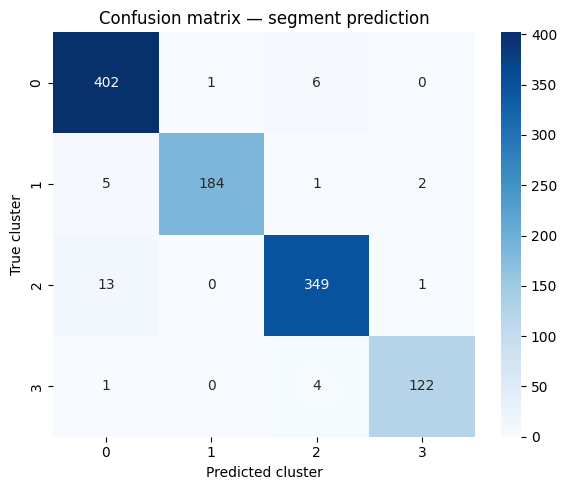

In [ ]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted cluster')
plt.ylabel('True cluster')
plt.title('Confusion matrix — segment prediction')
plt.tight_layout()
plt.show()


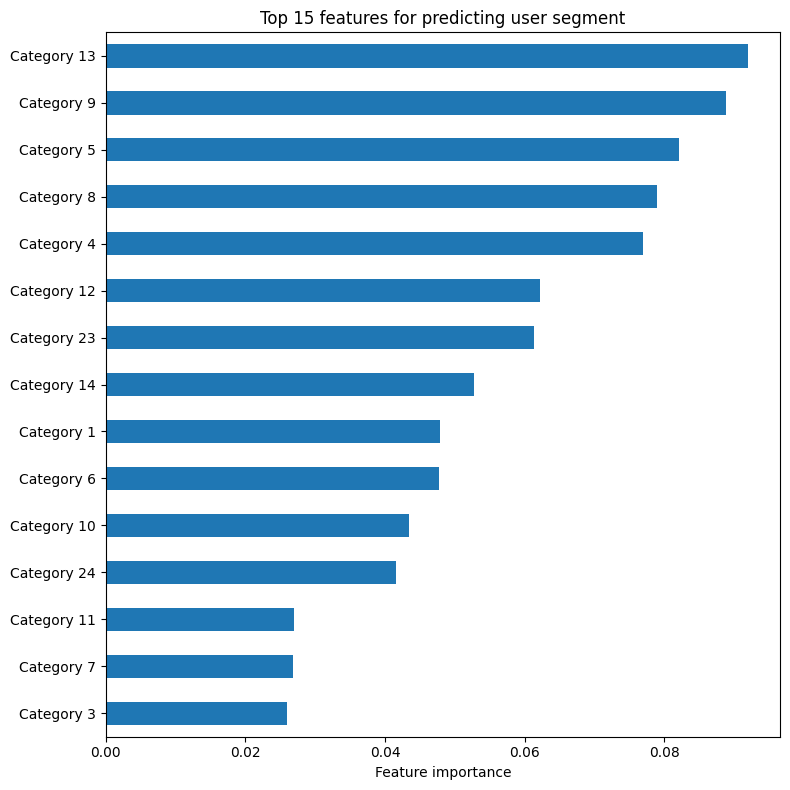

Category 13    0.091942
Category 9     0.088843
Category 5     0.082088
Category 8     0.079002
Category 4     0.076895
Category 12    0.062165
Category 23    0.061263
Category 14    0.052720
Category 1     0.047870
Category 6     0.047774
dtype: float64


In [ ]:
# Which categories matter most for predicting segment membership?
importances = pd.Series(clf.feature_importances_, index=feature_cols).sort_values(ascending=False)
plt.figure(figsize=(8, 8))
importances.head(15).plot(kind='barh')
plt.gca().invert_yaxis()
plt.xlabel('Feature importance')
plt.title('Top 15 features for predicting user segment')
plt.tight_layout()
plt.show()

print(importances.head(10))


## 7. Second model for comparison


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC

models = {
    'Random Forest': clf,
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=RANDOM_STATE, class_weight='balanced'),
    'SVM (RBF)': SVC(kernel='rbf', random_state=RANDOM_STATE, class_weight='balanced'),
}

# Accuracy alone can be misleading with imbalanced clusters (2043 vs 637 users),
# so we report Precision/Recall/F1 (weighted average across clusters) too.
# 5-fold stratified CV gives a validation score beyond the single train/test split.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

results = []
confusion_matrices = {}
for name, model in models.items():
    if name != 'Random Forest':
        model.fit(X_train, y_train)
    preds = model.predict(X_test)
    cv_scores = cross_val_score(model, X, y, cv=cv, scoring='accuracy')

    results.append({
        'Model': name,
        'Accuracy': round(accuracy_score(y_test, preds), 4),
        'Precision': round(precision_score(y_test, preds, average='weighted'), 4),
        'Recall': round(recall_score(y_test, preds, average='weighted'), 4),
        'F1_Score': round(f1_score(y_test, preds, average='weighted'), 4),
        'CV_Accuracy_Mean': round(cv_scores.mean(), 4),
        'CV_Accuracy_Std': round(cv_scores.std(), 4),
    })
    confusion_matrices[name] = confusion_matrix(y_test, preds)

results_df = pd.DataFrame(results)
print(results_df)

                 Model  Accuracy  Precision  Recall  F1_Score  \
0        Random Forest    0.9688     0.9692  0.9688    0.9689   
1  Logistic Regression    0.9963     0.9964  0.9963    0.9963   
2            SVM (RBF)    0.9826     0.9829  0.9826    0.9826   

   CV_Accuracy_Mean  CV_Accuracy_Std  
0            0.9650           0.0016  
1            0.9925           0.0021  
2            0.9804           0.0033  


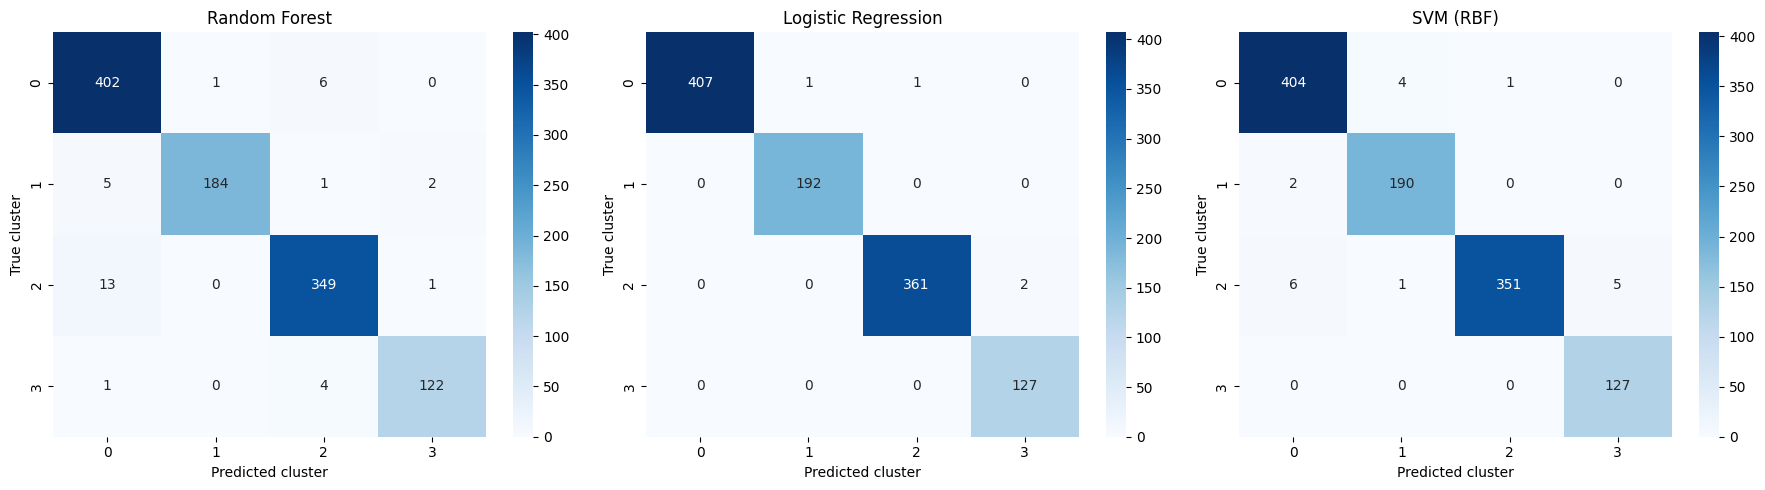

In [ ]:
# Confusion matrices for all three models, side by side
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (name, cm) in zip(axes, confusion_matrices.items()):
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax)
    ax.set_title(name)
    ax.set_xlabel('Predicted cluster')
    ax.set_ylabel('True cluster')
plt.tight_layout()
plt.show()

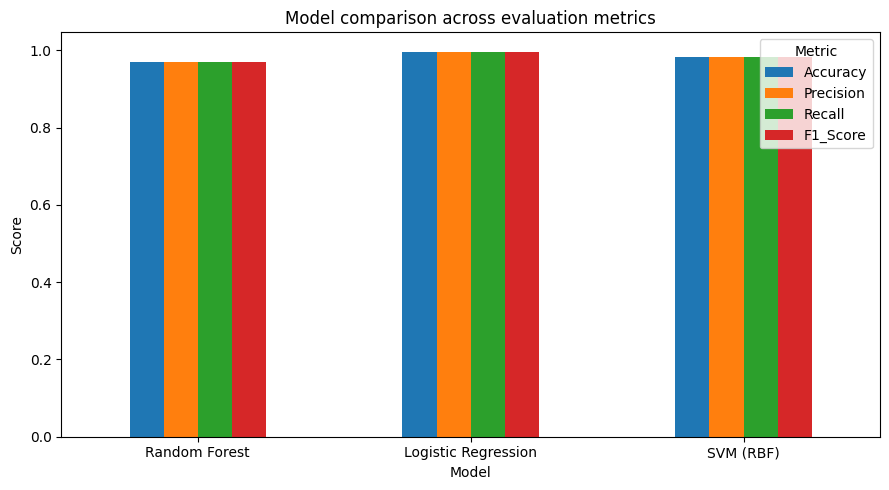

In [ ]:
# Bar chart comparing all models across the four metrics (for the report's Results section)
metrics_to_plot = ['Accuracy', 'Precision', 'Recall', 'F1_Score']
results_df.set_index('Model')[metrics_to_plot].plot(kind='bar', figsize=(9, 5))
plt.ylabel('Score')
plt.title('Model comparison across evaluation metrics')
plt.xticks(rotation=0)
plt.legend(title='Metric')
plt.tight_layout()
plt.show()

In [ ]:
# Cluster-labeled dataset — main file to bring into Power BI
df.to_csv("google_review_ratings_with_clusters.csv", index=False)

# Cluster profile summary — handy for a Power BI summary table/card visuals
cluster_profile.to_csv("cluster_profile_summary.csv")

# Model comparison table
results_df.to_csv("model_comparison_results.csv", index=False)

# Long-format cluster profile (Category / cluster / AvgRating) — easier to chart in Power BI
cluster_profile_long = cluster_profile.reset_index().melt(id_vars='cluster', var_name='Category', value_name='AvgRating')
cluster_profile_long.to_csv("cluster_profile_long.csv", index=False)

# Long-format confusion matrices (Model / ActualCluster / PredictedCluster / Count) — one file for all 3 models
cm_rows = []
for name, cm in confusion_matrices.items():
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            cm_rows.append({'Model': name, 'ActualCluster': i, 'PredictedCluster': j, 'Count': int(cm[i, j])})
pd.DataFrame(cm_rows).to_csv("confusion_matrices_long.csv", index=False)

print("Exported: google_review_ratings_with_clusters.csv, cluster_profile_summary.csv, model_comparison_results.csv, cluster_profile_long.csv, confusion_matrices_long.csv")


Exported: google_review_ratings_with_clusters.csv, cluster_profile_summary.csv, model_comparison_results.csv, cluster_profile_long.csv, confusion_matrices_long.csv


In [ ]:
from google.colab import files
files.download("google_review_ratings_cleaned.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>